# GPT-2 Fine-tuning Lab

Fine-tune GPT-2 (or DistilGPT-2) on a small custom text dataset and compare **before** (base model) and **after** (fine-tuned model) generations.

**Pipeline:** text preprocessing, tokenizer, training loop with loss monitoring, saved checkpoints, text generation, and a measure of how much your data influences the output.

Run the cells from top to bottom. On Google Colab or a laptop CPU use `distilgpt2` with a small dataset. `tiny-offline` is a random mini-model for checking the pipeline only (no download).

In [1]:
!pip install -q torch transformers tokenizers matplotlib

## 0. Settings

In [2]:
BASE_MODEL = 'distilgpt2'      # 'distilgpt2' | 'gpt2' | 'tiny-offline'
RUN_NAME   = 'my_run'
EPOCHS     = 3
BATCH_SIZE = 4
LR         = 5e-5
BLOCK_SIZE = 64
MAX_STEPS  = 0                # 0 = no cap
PROMPT     = 'Attention students:'
DATA_FILE  = 'campus_announcements.txt'   # replace with your own .txt file

## 1. Dataset

The starter dataset (30 campus announcements) is written to a file. To use your own data, upload a `.txt` file and set `DATA_FILE` above. Separate examples with a blank line, or put one example per line.

In [3]:
from pathlib import Path

SAMPLE = '''Attention students: the central library will extend its opening hours to midnight during the final examination week.

Attention students: registration for the spring semester opens on Monday at 9 AM on the student portal.

Reminder: the last date to submit the project proposal to your department office is Friday at 4 PM.

Attention students: the campus shuttle will run every 15 minutes between the main gate and the engineering block.

Notice: the cafeteria will be closed on Saturday for maintenance and will reopen on Sunday morning.

Attention students: the career fair will be held in the sports hall on Thursday, and more than 40 companies will attend.

Reminder: all students must renew their library cards before the end of the month to keep borrowing books.

Notice: the computer lab on the second floor will be closed for software updates on Wednesday afternoon.

Attention students: the annual science exhibition invites teams to register their projects at the student affairs office.

Attention students: scholarship applications for the new academic year must be submitted online before the deadline on the 20th.

Reminder: the student council meeting will take place in the main auditorium on Tuesday at 5 PM.

Notice: parking near the administration building is reserved for visitors until further notice.

Attention students: free workshops on resume writing and interview skills will be held at the career center this week.

Attention students: the campus clinic offers free health check-ups for all enrolled students every Monday morning.

Reminder: the deadline to drop a course without penalty is the end of the second week of the semester.

Notice: the main gate will be closed for construction, so please use the east entrance of the campus.

Attention students: the robotics club is recruiting new members, and no previous experience is required.

Attention students: mid-term examination timetables are now available on the student portal and on the department notice boards.

Reminder: please return all laboratory equipment to the store room before the semester break begins.

Notice: the university bookstore is offering a 20 percent discount on textbooks during orientation week.

Attention students: the international students office will host a welcome dinner in the student center on Friday evening.

Attention students: the swimming pool is open from 6 AM to 8 PM, and students must show their campus card at the entrance.

Reminder: tuition fees for the next semester must be paid at the finance office before the registration deadline.

Notice: the wireless network will be unavailable on campus for two hours tonight during a system upgrade.

Attention students: the debate society will hold open tryouts in the humanities building on Wednesday at 6 PM.

Attention students: graduation rehearsal for the final year class will take place in the main auditorium on Saturday morning.

Reminder: group study rooms in the library can be booked online up to three days in advance.

Notice: the campus bus service will follow a reduced schedule during the public holiday.

Attention students: the department of computer science invites everyone to a free seminar on artificial intelligence on Thursday afternoon.

Attention students: lost and found items can be collected from the security office between 9 AM and 5 PM.
'''

if not Path(DATA_FILE).exists():
    Path(DATA_FILE).write_text(SAMPLE)
    print('Wrote starter dataset to', DATA_FILE)

# Optional on Colab: upload your own file
# from google.colab import files; up = files.upload(); DATA_FILE = list(up)[0]

Wrote starter dataset to campus_announcements.txt


## 2. Backend code

The next cells define preprocessing, tokenizer, data blocks, the training loop, checkpoints and generation.

In [4]:
"""Backend core: text preprocessing, tokenizer, training loop, checkpoints, generation."""
import json
import math
import os
import random
import re
import time
from collections import Counter
from dataclasses import asdict, dataclass, field
from pathlib import Path

import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from transformers import GPT2Config, GPT2LMHeadModel, GPT2TokenizerFast

ROOT = Path.cwd()
TINY = "tiny-offline"          # random 2-layer GPT-2 + BPE tokenizer trained on your data (no download)
EOS = "<|endoftext|>"


def ckpt_root() -> Path:
    p = Path(os.environ.get("LAB_CKPT_DIR", ROOT / "checkpoints"))
    p.mkdir(parents=True, exist_ok=True)
    return p


def get_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 1. text preprocessing

In [5]:
def clean_text(raw: str) -> str:
    """Normalise line endings, remove control characters, collapse spaces, limit blank lines."""
    t = raw.replace("\r\n", "\n").replace("\r", "\n")
    t = re.sub(r"[\x00-\x08\x0b-\x1f\x7f]", " ", t)
    t = re.sub(r"[^\S\n]+", " ", t)
    t = re.sub(r" ?\n ?", "\n", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()


def split_examples(text: str, min_chars: int = 10) -> list[str]:
    """Blank lines separate examples; if there are none, every line is one example."""
    blocks = [b.strip() for b in re.split(r"\n\s*\n", text) if b.strip()]
    if len(blocks) <= 1:
        blocks = [ln.strip() for ln in text.split("\n") if ln.strip()]
    else:
        blocks = [b.replace("\n", " ") for b in blocks]
    return [b for b in blocks if len(b) >= min_chars]


STOP = set("""the and for with this that these those from are was were been will can may not all any each into than then
but about more most also have has had does your our their its you who what when where which while should must please""".split())


def words(text: str) -> list[str]:
    return re.findall(r"[a-z][a-z'-]+", text.lower())


def content_words(text: str) -> list[str]:
    return [w for w in words(text) if w not in STOP and len(w) > 3]


def top_keywords(texts: list[str], n: int = 25) -> list[str]:
    c = Counter(w for t in texts for w in content_words(t))
    return [w for w, _ in c.most_common(n)]


def dataset_stats(texts: list[str]) -> dict:
    return {"examples": len(texts), "words": sum(len(words(t)) for t in texts),
            "chars": sum(len(t) for t in texts), "keywords": top_keywords(texts, 15),
            "preview": texts[:3]}


def domain_influence(generated: str, vocab: set[str], keywords: list[str]) -> dict:
    """How much does a generation look like the custom data?"""
    cw = content_words(generated)
    if not cw:
        return {"coverage": 0.0, "keyword_hits": 0}
    return {"coverage": sum(w in vocab for w in cw) / len(cw),
            "keyword_hits": sum(w in keywords for w in cw)}

### 2. tokenizer + models

In [6]:
def build_tiny_tokenizer(texts: list[str], save_dir: Path) -> GPT2TokenizerFast:
    from tokenizers import ByteLevelBPETokenizer
    save_dir.mkdir(parents=True, exist_ok=True)
    bpe = ByteLevelBPETokenizer()
    bpe.train_from_iterator(texts, vocab_size=800, min_frequency=2, special_tokens=[EOS])
    bpe.save_model(str(save_dir))
    tok = GPT2TokenizerFast(vocab_file=str(save_dir / "vocab.json"), merges_file=str(save_dir / "merges.txt"),
                            unk_token=EOS, bos_token=EOS, eos_token=EOS)
    tok.save_pretrained(save_dir)
    return tok


def load_base(base_model: str, texts: list[str] | None = None, base_dir: Path | None = None):
    """Return (model, tokenizer) of the BASE model (before fine-tuning)."""
    if base_model != TINY:
        return GPT2LMHeadModel.from_pretrained(base_model), GPT2TokenizerFast.from_pretrained(base_model)
    if base_dir is not None and (base_dir / "config.json").exists():
        return GPT2LMHeadModel.from_pretrained(base_dir), GPT2TokenizerFast.from_pretrained(base_dir)
    tok = build_tiny_tokenizer(texts, base_dir)
    torch.manual_seed(0)
    cfg = GPT2Config(vocab_size=len(tok), n_positions=128, n_embd=64, n_layer=2, n_head=2,
                     bos_token_id=tok.eos_token_id, eos_token_id=tok.eos_token_id)
    model = GPT2LMHeadModel(cfg)
    model.save_pretrained(base_dir)
    return model, tok

### 3. dataset -> blocks

In [7]:
def _windows(ids: list[int], bs: int, stride: int) -> torch.Tensor:
    if len(ids) < bs:
        return torch.empty(0, bs, dtype=torch.long)
    return torch.tensor([ids[i:i + bs] for i in range(0, len(ids) - bs + 1, stride)], dtype=torch.long)


def prepare_data(texts: list[str], tok, block_size: int, val_frac: float = 0.1):
    """Tokenize, append EOS after each example, split train/val on the token stream, cut into blocks."""
    ids: list[int] = []
    for t in texts:
        ids += tok.encode(t) + [tok.eos_token_id]
    if len(ids) < 24:
        raise ValueError("Dataset is too small: at least ~24 tokens are needed.")
    bs = min(block_size, max(8, len(ids) // 5))
    n_val = max(bs + 1, int(len(ids) * val_frac))
    train_ids, val_ids = ids[:-n_val], ids[-n_val:]
    stride = bs if len(train_ids) > 20 * bs else max(1, bs // 2)   # overlap windows on tiny data
    train, val = _windows(train_ids, bs, stride), _windows(val_ids, bs, bs)
    return train, val, bs, {"tokens": len(ids), "train_blocks": len(train), "val_blocks": len(val), "block_size": bs}


@torch.no_grad()
def evaluate(model, blocks: torch.Tensor, device, batch_size: int = 8) -> float:
    model.eval()
    total, n = 0.0, 0
    for i in range(0, len(blocks), batch_size):
        x = blocks[i:i + batch_size].to(device)
        total += model(input_ids=x, labels=x).loss.item() * len(x)
        n += len(x)
    return total / max(n, 1)

### 4. training loop

In [8]:
@dataclass
class TrainConfig:
    base_model: str = "distilgpt2"
    run_name: str = "my_run"
    epochs: int = 3
    batch_size: int = 4
    lr: float = 5e-5
    block_size: int = 64
    max_steps: int = 0          # 0 = no cap
    seed: int = 42


@dataclass
class Progress:
    status: str = "idle"        # idle | preparing | training | done | stopped | error
    message: str = ""
    run: str = ""
    step: int = 0
    total_steps: int = 0
    epoch: int = 0
    train_log: list = field(default_factory=list)
    val_log: list = field(default_factory=list)
    stop: bool = False
    result: dict = field(default_factory=dict)


def save_checkpoint(model, tok, run_dir: Path, meta: dict) -> None:
    model.save_pretrained(run_dir / "model")
    tok.save_pretrained(run_dir / "model")
    (run_dir / "meta.json").write_text(json.dumps(meta, indent=2))


def train(texts: list[str], cfg: TrainConfig, prog: Progress | None = None) -> dict:
    prog = prog or Progress()
    prog.status, prog.run, prog.message = "preparing", cfg.run_name, "Loading base model and tokenizing"
    random.seed(cfg.seed); torch.manual_seed(cfg.seed)
    device = get_device()
    run_dir = ckpt_root() / cfg.run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    model, tok = load_base(cfg.base_model, texts, run_dir / "base_init")
    model.to(device)
    block = min(cfg.block_size, model.config.n_positions)
    train_blocks, val_blocks, block, info = prepare_data(texts, tok, block)

    spe = math.ceil(len(train_blocks) / cfg.batch_size)
    total = cfg.epochs * spe
    if cfg.max_steps:
        total = min(total, cfg.max_steps)
    warm = max(1, int(total * 0.1))
    opt = AdamW(model.parameters(), lr=cfg.lr, weight_decay=0.01)
    sched = LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    prog.total_steps = total

    v0 = evaluate(model, val_blocks, device)
    prog.val_log.append({"step": 0, "epoch": 0, "val_loss": v0, "ppl": math.exp(v0)})
    meta = {"run_name": cfg.run_name, "base_model": cfg.base_model, "config": asdict(cfg), "data": info,
            "keywords": top_keywords(texts), "initial_val_loss": v0, "device": str(device),
            "created": time.strftime("%Y-%m-%d %H:%M:%S")}
    (run_dir / "vocab.json").write_text(json.dumps(sorted({w for t in texts for w in words(t)})))

    prog.status, prog.message = "training", "Training"
    t0, step = time.time(), 0
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        order = torch.randperm(len(train_blocks))
        for i in range(0, len(order), cfg.batch_size):
            if step >= total or prog.stop:
                break
            x = train_blocks[order[i:i + cfg.batch_size]].to(device)
            loss = model(input_ids=x, labels=x).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
            step += 1
            prog.step, prog.epoch = step, epoch
            prog.train_log.append({"step": step, "epoch": epoch, "loss": loss.item(), "lr": sched.get_last_lr()[0]})
        v = evaluate(model, val_blocks, device)
        prog.val_log.append({"step": step, "epoch": epoch, "val_loss": v, "ppl": math.exp(v)})
        meta.update(final_val_loss=v, epochs_done=epoch, steps=step, seconds=round(time.time() - t0, 1))
        save_checkpoint(model, tok, run_dir, meta)           # checkpoint at the end of every epoch
        if step >= total or prog.stop:
            break

    prog.result = meta
    prog.status = "stopped" if prog.stop else "done"
    prog.message = "Stopped early (checkpoint saved)" if prog.stop else "Training finished"
    _CACHE.pop(cfg.run_name, None)
    return meta

### 5. runs + generation

In [9]:
_CACHE: dict = {}


def list_runs() -> list[dict]:
    out = []
    for p in sorted(ckpt_root().glob("*/meta.json")):
        try:
            out.append(json.loads(p.read_text()))
        except Exception:
            pass
    return out


def load_run(run: str):
    """Return (base_model, finetuned_model, tokenizer, meta). Cached."""
    if run in _CACHE:
        return _CACHE[run]
    rd = ckpt_root() / run
    if not (rd / "model" / "config.json").exists():
        raise FileNotFoundError(f"No checkpoint named '{run}'")
    meta = json.loads((rd / "meta.json").read_text())
    ft = GPT2LMHeadModel.from_pretrained(rd / "model")
    tok = GPT2TokenizerFast.from_pretrained(rd / "model")
    base = (GPT2LMHeadModel.from_pretrained(rd / "base_init") if meta["base_model"] == TINY
            else GPT2LMHeadModel.from_pretrained(meta["base_model"]))
    dev = get_device()
    _CACHE[run] = (base.to(dev).eval(), ft.to(dev).eval(), tok, meta)
    return _CACHE[run]


@torch.no_grad()
def generate(model, tok, prompt: str, max_new_tokens=60, temperature=0.8, top_k=50, top_p=0.95, seed=0) -> str:
    torch.manual_seed(seed)
    dev = next(model.parameters()).device
    ids = tok(prompt, return_tensors="pt").input_ids if prompt.strip() else torch.tensor([[tok.eos_token_id]])
    out = model.generate(ids.to(dev), attention_mask=torch.ones_like(ids).to(dev), do_sample=True,
                         max_new_tokens=max_new_tokens, temperature=max(temperature, 1e-3), top_k=top_k,
                         top_p=top_p, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0], skip_special_tokens=True)


def compare(run: str, prompt: str, n: int = 2, **kw) -> dict:
    """Same prompt + same seeds on the base and the fine-tuned model."""
    base, ft, tok, meta = load_run(run)
    vocab = set(json.loads((ckpt_root() / run / "vocab.json").read_text()))
    seed = kw.pop("seed", 0)
    res = {"base": [], "finetuned": []}
    for i in range(n):
        res["base"].append(generate(base, tok, prompt, seed=seed + i, **kw))
        res["finetuned"].append(generate(ft, tok, prompt, seed=seed + i, **kw))
    for k in res:
        m = [domain_influence(t, vocab, meta["keywords"]) for t in res[k]]
        res[k + "_metrics"] = {"coverage": sum(x["coverage"] for x in m) / n,
                               "keyword_hits": sum(x["keyword_hits"] for x in m)}
    res["val_loss"] = {"before": meta["initial_val_loss"], "after": meta["final_val_loss"]}
    return res

## 3. Preprocess and inspect the data

In [10]:
texts = split_examples(clean_text(Path(DATA_FILE).read_text()))
stats = dataset_stats(texts)
print(f"{stats['examples']} examples, {stats['words']} words")
print('Top keywords:', stats['keywords'])
for t in texts[:3]:
    print('-', t)

30 examples, 508 words
Top keywords: ['students', 'attention', 'notice', 'reminder', 'campus', 'student', 'office', 'during', 'week', 'semester', 'main', 'before', 'library', 'department', 'closed']
- Attention students: the central library will extend its opening hours to midnight during the final examination week.
- Attention students: registration for the spring semester opens on Monday at 9 AM on the student portal.
- Reminder: the last date to submit the project proposal to your department office is Friday at 4 PM.


## 4. Fine-tune with loss monitoring

In [11]:
cfg = TrainConfig(base_model=BASE_MODEL, run_name=RUN_NAME, epochs=EPOCHS, batch_size=BATCH_SIZE,
                  lr=LR, block_size=BLOCK_SIZE, max_steps=MAX_STEPS)
prog = Progress()
meta = train(texts, cfg, prog)
print(f"status: {prog.status} | steps: {prog.step} | device: {meta['device']} | time: {meta['seconds']}s")
print(f"validation loss: {meta['initial_val_loss']:.3f} (before) -> {meta['final_val_loss']:.3f} (after)")
print('checkpoint saved in:', ckpt_root() / RUN_NAME / 'model')

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

status: done | steps: 15 | device: cpu | time: 65.8s
validation loss: 4.517 (before) -> 3.354 (after)
checkpoint saved in: /content/checkpoints/my_run/model


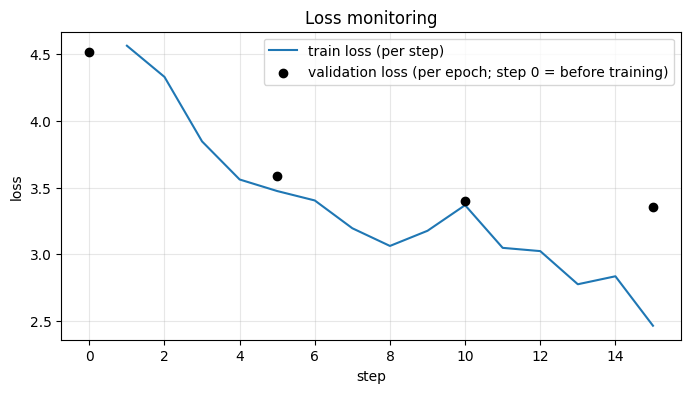

In [12]:
import matplotlib.pyplot as plt

steps = [p['step'] for p in prog.train_log]
plt.figure(figsize=(8, 4))
plt.plot(steps, [p['loss'] for p in prog.train_log], label='train loss (per step)')
plt.scatter([v['step'] for v in prog.val_log], [v['val_loss'] for v in prog.val_log], color='black', zorder=3, label='validation loss (per epoch; step 0 = before training)')
plt.xlabel('step'); plt.ylabel('loss'); plt.title('Loss monitoring'); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 5. Before vs after generation

Same prompt and same random seeds for both models, so differences come from fine-tuning.

In [15]:
def compare(run: str, prompt: str, n: int = 2, **kw) -> dict:
    """Same prompt + same seeds on the base and the fine-tuned model."""
    base, ft, tok, meta = load_run(run)
    vocab = set(json.loads((ckpt_root() / run / "vocab.json").read_text()))
    seed = kw.pop("seed", 0)
    res = {"base": [], "finetuned": []}
    for i in range(n):
        res["base"].append(generate(base, tok, prompt, seed=seed + i, **kw))
        res["finetuned"].append(generate(ft, tok, prompt, seed=seed + i, **kw))
    for k in ("base", "finetuned"):
        m = [domain_influence(t, vocab, meta["keywords"]) for t in res[k]]
        res[k + "_metrics"] = {"coverage": sum(x["coverage"] for x in m) / n,
                               "keyword_hits": sum(x["keyword_hits"] for x in m)}
    res["val_loss"] = {"before": meta["initial_val_loss"], "after": meta["final_val_loss"]}
    return res

In [16]:
res = compare(RUN_NAME, PROMPT, n=3, max_new_tokens=50, temperature=0.8, seed=1)

for i, (b, f) in enumerate(zip(res['base'], res['finetuned']), 1):
    print(f'--- sample {i} ---')
    print('BEFORE (base)      :', b)
    print('AFTER  (fine-tuned):', f)
    print()

--- sample 1 ---
BEFORE (base)      : Attention students:


















































AFTER  (fine-tuned): Attention students: the new student guide is free.

--- sample 2 ---
BEFORE (base)      : Attention students: The number of college students who are currently enrolled at the university has dropped significantly since the 2011 school year, the Pew Research Center found.























AFTER  (fine-tuned): Attention students: The faculty at the school has also invited students to submit proposals for applications to the Department of Education's online portal.

--- sample 3 ---
BEFORE (base)      : Attention students: this is a problem with the new language.


This is a problem with the new language. The language of the U.S. has some problems, but it has a lot of good and bad language.
It has good language and
AFTER  (fine-tuned): Attention students: this is the final lecture in the department office.



## 6. How much did the custom data influence the output?

**Coverage** = share of generated content words that appear in your dataset. **Keyword hits** = how many of the dataset's top keywords appear in the generations.

In [17]:
print(f"{'':14}{'coverage':>10}{'keyword hits':>14}")
for name, m in (('base', res['base_metrics']), ('fine-tuned', res['finetuned_metrics'])):
    print(f"{name:14}{m['coverage']*100:9.0f}%{m['keyword_hits']:14d}")
print(f"\nvalidation loss on your data: {res['val_loss']['before']:.3f} -> {res['val_loss']['after']:.3f}")

                coverage  keyword hits
base                 55%             7
fine-tuned           75%            14

validation loss on your data: 4.517 -> 3.354


## 7. Try your own prompts

In [18]:
for p in ['Reminder:', 'Notice:', 'The library']:
    r = compare(RUN_NAME, p, n=1, max_new_tokens=40, seed=5)
    print('PROMPT:', p)
    print('  base      :', r['base'][0])
    print('  fine-tuned:', r['finetuned'][0], '\n')

PROMPT: Reminder:
  base      : Reminder:








































  fine-tuned: Reminder:















 

PROMPT: Notice:
  base      : Notice:








































  fine-tuned: Notice:
























 

PROMPT: The library
  base      : The library is in the process of upgrading, but it is getting better and better,‍ so this year we‍ will continue to work on the library, but we‍ should still work on it
  fine-tuned: The library is open for the general public on Wednesday. 



## Notes

- With very little data the model overfits fast. If the validation dots rise while training loss keeps falling, use fewer epochs or a lower learning rate.
- To reload a saved model later: `GPT2LMHeadModel.from_pretrained('checkpoints/my_run/model')` (or the folder shown after training).
- Full GPT-2 fine-tuning on large data needs a GPU.